# Session 3 lecture: Cleaning and preparing data

<p class="lead">
Real data arrives with gaps, repeats, odd values, numbers stored as text and tables that do not quite fit together. Cleaning is not tidying up: every fix is a decision that can change the answer, so you make it deliberately and write it down.
</p>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aayush181509/AnalyticsLecture/blob/main/notebooks/03_cleaning_and_preparing_lecture.ipynb)

Open this notebook in Google Colab with the button above, then run each cell from top to bottom with **Shift + Enter**. Save your own copy with **File → Save a copy in Drive**.

---

## Recap quiz

Start by answering the quiz at the end of the Session 2 lecture, [`02_data_and_grain_lecture.md`](02_data_and_grain_lecture.md). Write your answers down before the discussion.

---

## What you will be able to explain

1. Why the raw data is never overwritten, and what a **cleaning log** records.
2. Three reasons data goes **missing**, and when to drop, flag or keep a missing value.
3. The difference between a **duplicate** and a **legitimate repeat**.
4. Why an **outlier** is something to investigate, not something to delete.
5. How to turn numbers and dates stored as **text** into real numbers and dates, safely.
6. **Join types** and **cardinality**, and how a join can silently multiply rows.
7. How to **reshape** a table between wide and long.

| Part | Topic |
|---|---|
| 1 | Raw data and the cleaning log |
| 2 | Missing data |
| 3 | Duplicates |
| 4 | Outliers |
| 5 | Text, numbers, dates and encodings |
| 6 | Joins and cardinality |
| 7 | Reshaping |
| 8 | Worked case: World Cup attendance |

> **How to use this notebook**
>
> When you see **Predict, then reveal**, write your guess first and only then run the cell. Every demonstration uses a small made-up table, so you can see the whole problem at once. The worked case at the end uses real data.

Run the next cell first. It loads the libraries, sets the chart style and defines `fetch`, which downloads a file and checks it is exactly the version this lecture was written for.

In [1]:
import hashlib
import io
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def fetch(url, expected_sha256):
    """Download a file into memory and check its SHA-256 fingerprint."""
    with urllib.request.urlopen(url) as response:
        data = response.read()
    if hashlib.sha256(data).hexdigest() != expected_sha256:
        print("WARNING: this file has changed since the course was written:", url)
        print("Your numbers may differ from the lecture. Ask your facilitator.")
    return data


pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a"]),
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})
print("Setup complete.")

Setup complete.


---

## Part 1: Raw data and the cleaning log

Two rules come before any cleaning technique.

1. **Never overwrite the raw data.** Read the original file, clean a **copy** in code, and keep the original exactly as it arrived. If a decision turns out wrong, you can rerun from the start.
2. **Log every change.** A cleaning log records what changed, why, and how many rows or values it affected. A reader who sees your result can then see exactly how you got there.

| Step | What changed | Why | Rows before | Rows after | Check |
|---|---|---|---|---|---|
| 1 | Removed exact duplicate rows | Same match loaded twice | … | … | Match count equals the official count |
| 2 | Converted attendance text to numbers | Stored with dots as thousands separators | … | … | No values lost; totals plausible |

In pandas, the habit looks like this: `clean = raw.copy()`, then change `clean`, and print a row count after every step.

> **Remember**
>
> Cleaning code is part of the analysis. If you fix something by hand in a spreadsheet, nobody (including you next month) can repeat it.

---

## Part 2: Missing data

A blank cell is not just an empty space: **why** it is empty decides what you can safely do with it. There are three broad reasons.

| Type | Plain meaning | Example | Risk if you just ignore the blanks |
|---|---|---|---|
| **Missing completely at random** (MCAR) | Blanks happen by chance, unrelated to anything | A scanner randomly fails on some parcels | Fewer rows, but averages stay fair |
| **Missing at random** (MAR) | Blanks depend on **another** column you can see | One warehouse never records delivery times | Averages lean towards the warehouses that do record |
| **Missing not at random** (MNAR) | Blanks depend on the **missing value itself** | Very late deliveries are the ones nobody logs | Averages are biased, and the data cannot show it |

The made-up example below has 200 deliveries. We know every true delivery time, then hide some of them in two different ways.

In [2]:
rng = np.random.default_rng(3)
true_days = rng.gamma(shape=3, scale=1.5, size=200).round(1)
deliveries = pd.DataFrame({"delivery_days": true_days})

# MCAR: hide 25% of values purely at random.
random_blank = rng.random(200) < 0.25
deliveries["recorded_mcar"] = deliveries["delivery_days"].mask(random_blank)

# MNAR: the later the delivery, the more likely nobody recorded it.
late_blank = rng.random(200) < (deliveries["delivery_days"] / deliveries["delivery_days"].max())
deliveries["recorded_mnar"] = deliveries["delivery_days"].mask(late_blank)

deliveries.head(8)

,delivery_days,recorded_mcar,recorded_mnar
0,11.40,11.40,NaN
1,5.10,5.10,NaN
2,3.00,3.00,3.00
3,0.80,0.80,0.80
4,2.20,2.20,2.20
5,4.60,NaN,NaN
6,3.30,3.30,3.30
7,1.90,NaN,1.90


### Predict, then reveal

Both recorded columns have some values hidden. pandas skips blanks when it computes a mean. Which recorded mean will be close to the true mean, and which will be too low?

In [3]:
summary = pd.DataFrame({
    "values_present": deliveries.notna().sum(),
    "mean_days": deliveries.mean(),
})
summary

,values_present,mean_days
delivery_days,200,4.79
recorded_mcar,143,4.65
recorded_mnar,132,4.00


The randomly hidden column keeps a fair average, because the blanks are a random sample. The second column loses mostly the **late** deliveries, so its average looks better than reality, and nothing in the recorded data warns you.

### Drop, flag or keep?

| Choice | What you do | Use it when |
|---|---|---|
| **Drop** | Remove rows with the blank | Blanks are few and plausibly random, **and** you report how many you dropped |
| **Flag** | Add a column such as `delivery_missing = 1` and keep the row | The fact that a value is missing is itself information |
| **Keep as missing** | Leave `NaN`, let each calculation skip it, and say so | Most of the time: it is honest and reversible |
| **Fill (impute)** | Replace the blank with an estimate | Only with a stated method and a reason; never silently, never with 0 unless 0 is true |

pandas makes flagging and counting easy:

In [4]:
deliveries["mnar_missing"] = deliveries["recorded_mnar"].isna().astype(int)
print("Missing values:", deliveries["mnar_missing"].sum(), "of", len(deliveries))
print("Share missing: ", f"{deliveries['mnar_missing'].mean():.0%}")

Missing values: 68 of 200
Share missing:  34%


> **Check your understanding 1**
>
> A customer survey asks for household income. The income question is left blank more often by people with very high incomes. Which type of missingness is this? What happens to the average income if you simply drop the blanks, and what would you write in your report?

> **A common mistake**
>
> Filling blanks with `0` (`fillna(0)`) turns "we do not know" into "it was zero". A missing sales figure is not zero sales, and a missing delivery time is not a same-day delivery.

---

## Part 3: Duplicates

A **duplicate** is the same real-world event recorded more than once: a file loaded twice, a form submitted twice. A **legitimate repeat** is two real events that happen to look alike: a customer who really did buy the same item twice on one day.

The difference is **not** visible from the values alone. You decide using the grain and the keys from Session 2.

In [5]:
lines = pd.DataFrame({
    "line_id":  [101, 102, 103, 103, 104],
    "order_id": ["A1", "A1", "A2", "A2", "A3"],
    "product":  ["Pen", "Pen", "Desk", "Desk", "Lamp"],
    "quantity": [1, 1, 1, 1, 2],
})
lines

,line_id,order_id,product,quantity
0,101,A1,Pen,1
1,102,A1,Pen,1
2,103,A2,Desk,1
3,103,A2,Desk,1
4,104,A3,Lamp,2


### Predict, then reveal

How many rows does `duplicated()` mark, and are they all mistakes? Look at `line_id` and `order_id` before you run the cell.

In [6]:
print("Exact duplicate rows:        ", lines.duplicated().sum())
print("Repeats ignoring line_id:    ", lines.duplicated(subset=["order_id", "product", "quantity"]).sum())
lines[lines.duplicated(keep=False)]

Exact duplicate rows:         1
Repeats ignoring line_id:     2


,line_id,order_id,product,quantity
2,103,A2,Desk,1
3,103,A2,Desk,1


- Line **103** appears twice with **every** value equal, including its own key. That is a true duplicate: the same line loaded twice. Remove one copy.
- Lines **101** and **102** share the order and product but have **different line IDs**. Two pens on two lines is a legitimate repeat. Removing one would lose a real sale.

| Check | pandas | What it finds |
|---|---|---|
| Exact duplicate rows | `df.duplicated()` | Rows equal in every column |
| Repeats on chosen columns | `df.duplicated(subset=[...])` | Rows equal on the columns that define one real event |
| Is the key unique? | `df["key"].is_unique` | Whether the primary key can be trusted |
| Show all copies | `df[df.duplicated(keep=False)]` | Both the first copy and its repeats, to inspect |
| Remove exact duplicates | `df.drop_duplicates()` | Keeps the first copy of each |

> **Check your understanding 2**
>
> A payments table has two rows with the same customer, amount and date, but different `payment_id` values. Are they duplicates? What extra information would you look for before deciding?

---

## Part 4: Outliers

An **outlier** is a value far from the rest. Some are **errors** (a typing slip adds a zero). Some are **real and important** (one huge corporate order). Detecting an outlier is mechanical; deciding what it means is not.

A common rule flags values more than 1.5 × IQR beyond the quartiles. The **IQR** (interquartile range) is the distance between the 25th and 75th percentiles; you will meet it properly in Session 4.

In [7]:
order_values = pd.Series(
    [42, 55, 38, 61, 47, 53, 49, 58, 44, 51, 4900, 1250],
    index=[f"O{i:02d}" for i in range(1, 13)],
    name="order_value",
)

q1, q3 = order_values.quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f"Flag values below {low:,.1f} or above {high:,.1f}")
order_values[(order_values < low) | (order_values > high)]

Flag values below 27.5 or above 77.5


O11    4900
O12    1250
Name: order_value, dtype: int64

### Predict, then reveal

Two orders are flagged. Suppose a check with the sales team shows that **O11** was typed as 4900 instead of 49.00, and **O12** is a genuine bulk order from a school. What happens to the average if you delete both, and what if you fix only the error?

In [8]:
fixed = order_values.copy()
fixed["O11"] = 49.00  # confirmed typing error, corrected with a logged reason

pd.Series({
    "Average, raw": order_values.mean(),
    "Average, both outliers deleted": order_values.drop(["O11", "O12"]).mean(),
    "Average, error fixed, real order kept": fixed.mean(),
    "Median, raw": order_values.median(),
})

Average, raw                            554.00
Average, both outliers deleted           49.80
Average, error fixed, real order kept   149.75
Median, raw                              52.00
dtype: float64

Deleting both outliers hides a real customer and understates the business. Fixing only the confirmed error gives the honest figure. Notice also that the **median** hardly moves: it resists extreme values, which is why it suits skewed data (Session 4).

| Situation | Action |
|---|---|
| Confirmed error with a known correct value | Fix it, log the old and new value and the evidence |
| Impossible value (negative age, date in the future) and no correction available | Set to missing and flag it |
| Real but extreme | Keep it; consider reporting the median too, or showing results with and without it |
| Not sure | Keep it, flag it, and ask the data owner |

> **Check your understanding 3**
>
> A shipping table has one shipment that took 210 days. Give one explanation that makes it an error and one that makes it real. What would you do before your report goes out?

---

## Part 5: Text, numbers, dates and encodings

Files often store numbers and dates as **text**. pandas then cannot add them up, sort them correctly or compare them with dates.

### Numbers with thousands separators

Many countries write one million and a half as **1.500.000** and use the comma for decimals. Python reads a dot as a decimal point.

In [9]:
attendance_text = pd.Series(["590.549", "1.045.246", "363.000", "819.810"], name="attendance")

naive = pd.to_numeric(attendance_text, errors="coerce")
careful = pd.to_numeric(attendance_text.str.replace(".", "", regex=False))

pd.DataFrame({"text": attendance_text, "naive": naive, "careful": careful})

,text,naive,careful
0,590.549,590.55,590549
1,1.045.246,NaN,1045246
2,363.000,363.00,363000
3,819.810,819.81,819810


### Predict, then reveal (look at the output above)

- The **naive** conversion reads `590.549` as five hundred and ninety, and it cannot read `1.045.246` at all, so `errors="coerce"` silently turned it into `NaN`.
- The **careful** version removes the dots first, so every value becomes a whole number.

`errors="coerce"` is useful, but always count how many values became `NaN`: each one is a value you just lost.

### Dates written as text

`03/04/2024` is the 3rd of April in most of the world and March 4th in the United States. Tell pandas the format instead of letting it guess.

In [10]:
date_text = pd.Series(["03/04/2024", "15/04/2024", "28/02/2024"])

day_first = pd.to_datetime(date_text, format="%d/%m/%Y")
print(day_first.dt.strftime("%d %B %Y").tolist())

month_first = pd.to_datetime(date_text, format="%m/%d/%Y", errors="coerce")
print("Values that fail as month/day/year:", month_first.isna().sum())

['03 April 2024', '15 April 2024', '28 February 2024']
Values that fail as month/day/year: 2


### Encodings and stray spaces

Text is stored as bytes, and the **encoding** says how to turn bytes into letters. When a file is saved in one encoding and read in another, letters such as **ô** or **é** come out as strange symbols. If the symbol is the Unicode replacement character, the original letter is **lost**: you can only restore it from outside knowledge.

Invisible spaces cause a quieter problem: `"Paris "` and `"Paris"` look identical on screen but count as two different cities.

In [11]:
cities = pd.Series(["Paris", "Paris ", " Lyon", "Lyon", "Malm\ufffd"])
print("Different values before strip:", cities.nunique())
print("Different values after strip: ", cities.str.strip().nunique())
print("Values containing the replacement character:", cities.str.contains("\ufffd").sum())

Different values before strip: 5
Different values after strip:  3
Values containing the replacement character: 1


| Problem | Detect | Fix |
|---|---|---|
| Numbers stored as text | `df.dtypes` shows `object` | `pd.to_numeric`, after removing separators; count new `NaN`s |
| Dates stored as text | `object` type; odd sorting | `pd.to_datetime(..., format=...)` |
| Leading or trailing spaces | `(s != s.str.strip()).sum()` | `s.str.strip()` |
| Broken characters | `s.str.contains("\ufffd")` | Flag; correct from a trusted list, never by guessing |
| Different spellings of one thing | `value_counts()` | A documented mapping, e.g. `{"IR Iran": "Iran"}` |

> **Check your understanding 4**
>
> After `pd.to_numeric(..., errors="coerce")` a column of 5,000 prices has 37 `NaN` values that were not there before. What do you do next, and what goes in the cleaning log?

---

## Part 6: Joins and cardinality

A **join** (`merge` in pandas) puts columns from two tables side by side by matching a key. Two choices decide the result.

**1. Which rows to keep (`how`)**

| `how=` | Keeps |
|---|---|
| `"inner"` | Only keys found in **both** tables |
| `"left"` | Every row of the left table; blanks where the right has no match |
| `"right"` | Every row of the right table |
| `"outer"` | Every key from either table |

**2. Cardinality: how many matches each key has**

| Cardinality | Meaning | Example | Row count after a left join |
|---|---|---|---|
| **One-to-one** | Each key once on both sides | Employee ↔ employee contract | Unchanged |
| **Many-to-one** | Many left rows share one right row | Order lines → region manager | Unchanged |
| **One-to-many** | One left row matches many right rows | Order → its lines | **Grows** |
| **Many-to-many** | Keys repeat on both sides | Orders by region × campaigns by region | **Multiplies** |

In [12]:
orders = pd.DataFrame({
    "order_id": ["A1", "A2", "A3", "A4"],
    "region":   ["North", "North", "South", "East"],
    "sales":    [100, 250, 80, 120],
})
managers = pd.DataFrame({
    "region":  ["North", "South", "West"],
    "manager": ["Asha", "Ben", "Chen"],
})

joined = orders.merge(managers, on="region", how="left", validate="many_to_one", indicator=True)
print("Rows before:", len(orders), "| rows after:", len(joined))
joined

Rows before: 4 | rows after: 4


,order_id,region,sales,manager,_merge
0,A1,North,100,Asha,both
1,A2,North,250,Asha,both
2,A3,South,80,Ben,both
3,A4,East,120,NaN,left_only


`indicator=True` adds a `_merge` column showing where each row found a match: **East** has no manager (`left_only`), and the manager for **West** has no orders, so that row does not appear in a left join. `validate="many_to_one"` makes pandas **check** that each region appears only once in `managers`.

### Predict, then reveal: the row explosion

North changed manager during the year, so someone adds a second North row to the managers table. Sales are then totalled from the joined table. What happens to total Sales?

In [13]:
managers_history = pd.DataFrame({
    "region":  ["North", "North", "South", "West"],
    "manager": ["Asha", "Dev", "Ben", "Chen"],
})

exploded = orders.merge(managers_history, on="region", how="left")
print("Rows before:", len(orders), "| rows after:", len(exploded))
print("Total sales before the join:", orders["sales"].sum())
print("Total sales after the join: ", exploded["sales"].sum())

Rows before: 4 | rows after: 6
Total sales before the join: 550
Total sales after the join:  900


Each North order now matches **two** manager rows, so it appears twice and its sales are counted twice. No error appears. This is the most common way joins go wrong.

`validate` turns the silent mistake into a loud one:

In [14]:
try:
    orders.merge(managers_history, on="region", how="left", validate="many_to_one")
except pd.errors.MergeError as problem:
    print("MergeError:", problem)

MergeError: Merge keys are not unique in right dataset; not a many-to-one merge


> **Remember: three checks for every join**
>
> 1. Before: is the key unique on the side that should be unique? (`df["key"].is_unique`)
> 2. During: `validate=` with the cardinality you expect, and `indicator=True` to see unmatched rows.
> 3. After: compare row counts and one total (such as Sales) before and after.

> **Check your understanding 5**
>
> You left-join 6,000 order lines to a product table on `product_id` and get 6,240 rows. What does that tell you about the product table? Which `validate` value would have caught it?

---

## Part 7: Reshaping

The same numbers can be laid out **wide** (one column per month, easy to read) or **long** (one row per item per month, easy to filter, group and chart). Session 2 called the long layout **tidy**.

In [15]:
wide = pd.DataFrame({
    "store": ["Central", "Harbour"],
    "Jan": [120, 95],
    "Feb": [130, 101],
    "Mar": [125, 110],
})
long = wide.melt(id_vars="store", var_name="month", value_name="sales")
long

,store,month,sales
0,Central,Jan,120
1,Harbour,Jan,95
2,Central,Feb,130
3,Harbour,Feb,101
4,Central,Mar,125
5,Harbour,Mar,110


In [16]:
back_to_wide = long.pivot(index="store", columns="month", values="sales")[["Jan", "Feb", "Mar"]]
print("Same total before and after reshaping:", wide[["Jan", "Feb", "Mar"]].sum().sum() == back_to_wide.sum().sum())
back_to_wide

Same total before and after reshaping: True


month,Jan,Feb,Mar
store,,,
Central,120,130,125
Harbour,95,101,110


| Function | Direction | Typical use |
|---|---|---|
| `melt` | wide → long | Columns that are really values of a variable (months, years, products) |
| `pivot` | long → wide | A readable table for a report |
| `pivot_table` | long → wide, with a summary | When pairs repeat and need adding up |

A quick total before and after reshaping catches lost or duplicated values.

> **Check your understanding 6**
>
> `long.pivot(...)` raises an error saying the index contains duplicate entries. What does that tell you about the long table, and which function would you use instead?

---

## Part 8: Worked case — World Cup attendance

The **World Cup results** workbook from Tableau's sample-data page has a sheet called `WorldCups`, with one row per tournament since 1930. We want total attendance per tournament.

> **About the data**
>
> The workbook was compiled for *Sports Viz Sundays 2018* and is published in Tableau's sample-data catalog. We download it from that source for learning; we do not redistribute it, and the course does not claim a licence for it.

In [17]:
WORLD_CUP_URL = "https://public.tableau.com/app/sample-data/world_cup_results.xlsx"
WORLD_CUP_SHA256 = "dbad641c16c914c14fef0c95bf6f918fa5d2746671e4dc269b6a1ec3e2a3cc45"

world_cup_bytes = fetch(WORLD_CUP_URL, WORLD_CUP_SHA256)
cups = pd.read_excel(io.BytesIO(world_cup_bytes), sheet_name="WorldCups")
cups[["Year", "Country", "MatchesPlayed", "Attendance"]].head(8)

,Year,Country,MatchesPlayed,Attendance
0,1930,Uruguay,18,590.55
1,1934,Italy,17,363
2,1938,France,18,375.70
3,1950,Brazil,22,1.045.246
4,1954,Switzerland,26,768.61
5,1958,Sweden,35,819.81
6,1962,Chile,32,893.17
7,1966,England,32,1.563.135


### Step 1: Profile the column

The `Attendance` values look like numbers with dots. Check what Python actually stored in each cell.

In [18]:
print("Column type:", cups["Attendance"].dtype)
cups["Attendance"].map(lambda value: type(value).__name__).value_counts()

Column type: object


Attendance
str      14
float     5
int       1
Name: count, dtype: int64

The column mixes **text** and **numbers**. Excel stored the big values (two dots) as text, but read values with one dot as **decimal numbers**: `590.549` became five hundred and ninety point five (pandas shows it rounded as `590.55`), and `375.700` lost its trailing zeros to become `375.7`.

### Step 2: Predict, then reveal

If you just convert the column with `pd.to_numeric`, what will the 1930 value be, and how many values will fail?

In [19]:
naive = pd.to_numeric(cups["Attendance"], errors="coerce")
print("Values that failed:", naive.isna().sum(), "of", len(cups))
naive.head(4)

Values that failed: 14 of 20


0   590.55
1   363.00
2   375.70
3      NaN
Name: Attendance, dtype: float64

### Step 3: A careful conversion

Each kind of cell needs its own rule:

- **Text** such as `"1.045.246"`: remove the dots.
- **Numbers** such as `590.549` or `375.7`: these were thousands, so multiply by 1,000 and round.

In [20]:
def parse_attendance(value):
    if isinstance(value, str):
        return int(value.replace(".", ""))
    return int(round(value * 1000))


cups["attendance"] = cups["Attendance"].map(parse_attendance)
cups["attendance_per_match"] = cups["attendance"] / cups["MatchesPlayed"]
cups[["Year", "Attendance", "attendance", "attendance_per_match"]].head(8)

,Year,Attendance,attendance,attendance_per_match
0,1930,590.55,590549,"32,808.28"
1,1934,363,363000,"21,352.94"
2,1938,375.70,375700,"20,872.22"
3,1950,1.045.246,1045246,"47,511.18"
4,1954,768.61,768607,"29,561.81"
5,1958,819.81,819810,"23,423.14"
6,1962,893.17,893172,"27,911.62"
7,1966,1.563.135,1563135,"48,847.97"


### Step 4: Check the result is plausible

A conversion can run without errors and still be wrong. Plot attendance **per match**: if any value were off by a factor of 1,000, it would stand out at once.

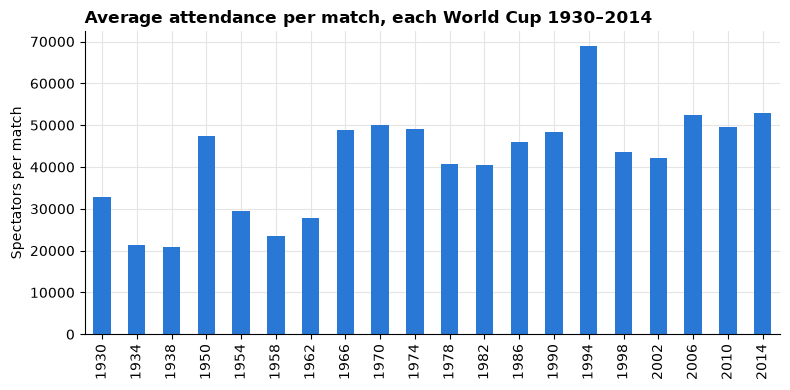

In [21]:
ax = cups.plot(x="Year", y="attendance_per_match", kind="bar", legend=False,
               title="Average attendance per match, each World Cup 1930–2014")
ax.set_xlabel("")
ax.set_ylabel("Spectators per match")
plt.tight_layout()
plt.show()

> **What the worked case shows**
>
> - The problem was invisible in the first five rows and only appeared when we profiled the **types**.
> - The fix needed a **reason** for each rule (why multiply by 1,000), which belongs in the cleaning log.
> - A **plausibility chart** is a cheap final check: no bar is a thousand times too small.

In the lab you clean the match-level sheet of the same workbook, where the problem is duplicated matches rather than text numbers.

---

## Summary

- Keep the raw file untouched; clean a copy in code and log every change with before and after counts.
- Ask **why** data is missing before you drop or fill anything. Missing is not zero.
- Duplicates are judged against the grain and keys. Identical-looking rows can be real.
- Outliers are investigated, not deleted: fix confirmed errors, keep real extremes.
- Parse text numbers and dates with explicit rules, and count every value that fails.
- Know the cardinality of every join; use `validate=`, `indicator=True` and row-count checks.
- `melt` and `pivot` reshape tables; check totals before and after.

---

## Quiz

Answer these at the start of the next lecture. Write your answers before the discussion.

1. Explain the difference between data missing **at random** and **not at random**, with a business example of each.
2. Why is `fillna(0)` usually wrong for a missing sales value?
3. Two rows in a table are identical in every column except their ID. Are they duplicates? What decides it?
4. Give two different actions you might take for an outlier, and when each is right.
5. What does `pd.to_numeric(..., errors="coerce")` do to a value it cannot parse, and why must you count those values?
6. A left join increases the number of rows. What does that tell you about the right-hand table?
7. What does `validate="many_to_one"` check, and what happens if the check fails?
8. Name two things a cleaning log should record for every step.

---

## Lab briefing

In the **Lab** you will:

- clean the World Cup **match** results: find duplicated matches, check them against the official tournament totals, and fix text problems;
- diagnose missing dates in a **mobile operating system** usage file and decide which part of it can be trusted;
- **join** the three sheets of the Superstore workbook with every check from Part 6;
- debug a colleague's join that inflates sales.

Bring your evidence log. Continue with the [Session 3 lab](03_cleaning_and_preparing_lab.md).